# 5 · How much to trust the line, and how much rain is still missing

Three questions a threshold leaves open, answered from data that is in the repository. No network.

1. **How well does the line fit here?** A T5 threshold is fitted so that 5 % of the landslides of a macroregion sit below it. Inside a macroregion, a region can be far from that.
2. **How much rain is still missing?** With a storm going on, what the line asks if it goes on for one, three, six more hours.
3. **What did others publish?** The thresholds of the literature for a region, with their sources.

Then the same assessment as a record other libraries can read.

> **A threshold exceeded is not an alert.** The official alert in Italy is the criticality bulletin of the Dipartimento della Protezione Civile.

Data: e-ITALICA v4 (Brunetti et al. 2024), CC BY 4.0 · DPC SRT1, © Dipartimento della Protezione Civile, CC BY-SA 4.0.

In [1]:
import csv
import json
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

from rainfall_thresholds import (
    CALIBRATION,
    EXPECTED_BELOW,
    ITALICA_T5,
    cumulate,
    event_against_threshold,
    load_regional_catalogue,
    macroregion_of,
    rain_to_threshold,
)

SERIES = Path("../benchmarks/series")


def read(name):
    with (SERIES / name).open(encoding="utf-8") as f:
        rows = csv.DictReader(line for line in f if not line.startswith("#"))
        return {
            datetime.fromisoformat(r["time"].replace("Z", "+00:00")): float(r["mm"])
            if r["mm"]
            else None
            for r in rows
        }

## 1. How well does the line fit here?

`CALIBRATION` counts, for each region, the e-ITALICA landslides the thresholds were fitted on and how many are below the threshold of their macroregion. `interval()` is the range the real share can be in, given how many landslides there are. `position` reads it against the 5 %: `high` means the line sits high for that region and misses more of its landslides, `low` that rain crosses it more easily there.

In [2]:
print(f"{'region':<24}{'landslides':>11}{'below':>7}{'share':>8}{'95 % interval':>18}   line here")
for c in sorted(CALIBRATION.values(), key=lambda c: -c.below_share):
    low, high = c.interval()
    print(
        f"{c.region:<24}{c.events:>11}{c.below:>7}{100 * c.below_share:>7.1f}%"
        f"{100 * low:>9.1f} - {100 * high:>4.1f}%   {c.position}"
    )

region                   landslides  below   share     95 % interval   line here
Valle d'Aosta                    68     11   16.2%      9.3 - 26.7%   high
Emilia-Romagna                   81     11   13.6%      7.8 - 22.7%   high
Trentino-Alto Adige             123     16   13.0%      8.2 - 20.1%   high
Sardegna                        216     24   11.1%      7.6 - 16.0%   high
Basilicata                       55      6   10.9%      5.1 - 21.8%   high
Umbria                          203     19    9.4%      6.1 - 14.2%   high
Abruzzo                         141     10    7.1%      3.9 - 12.6%   as fitted
Veneto                          144      9    6.2%      3.3 - 11.5%   as fitted
Molise                           17      1    5.9%      1.0 - 27.0%   as fitted
Puglia                          140      8    5.7%      2.9 - 10.9%   as fitted
Sicilia                         400     20    5.0%      3.3 -  7.6%   as fitted
Marche                         1131     55    4.9%      3.8 -  6.3%  

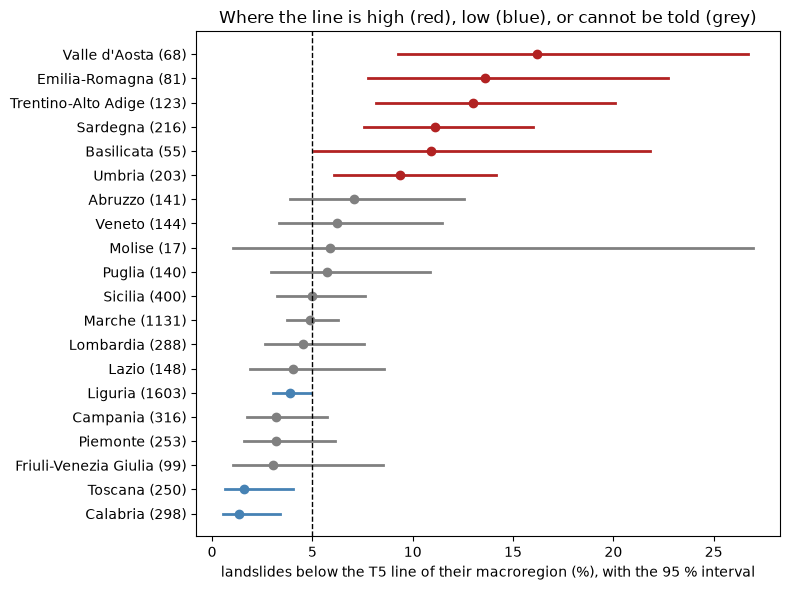

In [3]:
rows = sorted(CALIBRATION.values(), key=lambda c: c.below_share)
colour = {"high": "firebrick", "low": "steelblue", "as fitted": "grey"}
fig, ax = plt.subplots(figsize=(8, 6))
for y, c in enumerate(rows):
    low, high = c.interval()
    ax.plot([100 * low, 100 * high], [y, y], color=colour[c.position], lw=2)
    ax.plot(100 * c.below_share, y, "o", color=colour[c.position])
ax.axvline(100 * EXPECTED_BELOW, color="black", ls="--", lw=1)
ax.set_yticks(range(len(rows)), [f"{c.region} ({c.events})" for c in rows])
ax.set_xlabel("landslides below the T5 line of their macroregion (%), with the 95 % interval")
ax.set_title("Where the line is high (red), low (blue), or cannot be told (grey)")
plt.tight_layout()
plt.show()

Read it with care. This is how the line sits on the **landslides of the past, at rain gauges**. It does not say how often the line is crossed with no landslide: that needs the rain of ordinary days, which is the caller's (`skill`, on your own rain gauge). And a region in grey is not "well calibrated": Molise has 17 landslides, and its interval runs from 1 % to 27 %.

## 2. How much rain is still missing?

Melito di Porto Salvo, 10 October 2026, on the DPC radar. We stop the clock at 03:00 UTC, in the middle of the storm, and ask what the line of southern Italy asks if the rain goes on.

In [4]:
melito = read("melito-srt1.csv")
now = datetime.fromisoformat("2026-10-10T03:00+00:00")
so_far = {t: mm for t, mm in melito.items() if t <= now}
line = ITALICA_T5["southern"]

a = event_against_threshold(
    so_far, line, no_rain_break_hours=6, min_event_mm=2.0, choice="latest", source="DPC SRT1"
)
e = a.event
print(
    f"at {now:%d/%m %H:%M}: {e.total_mm:.1f} mm in {e.duration_hours:.0f} h, "
    f"{a.ratio:.2f} times the line"
)
print(
    "a lower bound" if a.at_least else "fully measured",
    "(the series stops here: the event may go on)",
)

for h, mm in rain_to_threshold(e, line, more_hours=(1, 3, 6, 24, 72)).items():
    asked = line.cumulated(e.duration_hours + h)
    print(
        f"  if it goes on {h:>2} h more: the line asks {asked:6.1f} mm in all, "
        f"still missing {mm:5.1f} mm"
    )

at 10/10 03:00: 96.6 mm in 16 h, 4.12 times the line
a lower bound (the series stops here: the event may go on)
  if it goes on  1 h more: the line asks   23.9 mm in all, still missing   0.0 mm
  if it goes on  3 h more: the line asks   24.9 mm in all, still missing   0.0 mm
  if it goes on  6 h more: the line asks   26.2 mm in all, still missing   0.0 mm
  if it goes on 24 h more: the line asks   32.4 mm in all, still missing   0.0 mm
  if it goes on 72 h more: the line asks   42.9 mm in all, still missing   0.0 mm


The storm is already above the line, so nothing is missing: the line would catch up only after days of almost no rain. The number is more useful **before** a storm crosses the line. Here is the same question asked every hour from the start: the rain fallen, and what was still missing for the next three hours.

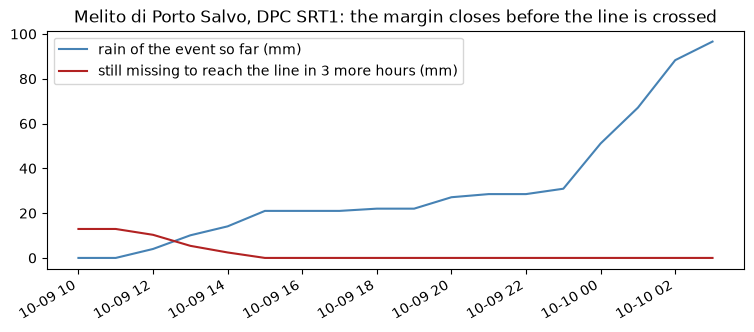

nothing missing from 09/10 15:00 UTC


In [5]:
hours = sorted(t for t in melito if datetime.fromisoformat("2026-10-09T10:00+00:00") <= t <= now)
fallen, missing = [], []
for t in hours:
    upto = {k: v for k, v in melito.items() if k <= t}
    found = event_against_threshold(
        upto, line, no_rain_break_hours=6, min_event_mm=0.1, choice="latest"
    )
    going = found is not None and t - found.event.end < timedelta(hours=6)
    event = found.event if going else None
    fallen.append(event.total_mm if event else 0.0)
    missing.append(rain_to_threshold(event, line, more_hours=(3,))[3])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(hours, fallen, color="steelblue", label="rain of the event so far (mm)")
ax.plot(
    hours, missing, color="firebrick", label="still missing to reach the line in 3 more hours (mm)"
)
ax.legend()
ax.set_title("Melito di Porto Salvo, DPC SRT1: the margin closes before the line is crossed")
fig.autofmt_xdate()
plt.show()
first_zero = next(t for t, mm in zip(hours, missing, strict=True) if mm == 0.0)
print(f"nothing missing from {first_zero:%d/%m %H:%M} UTC")

This is **not a forecast**: it supposes the rain does not stop, and says nothing on whether it will. Compare it with a forecast, or with the rain of the last hour. And the rain here is radar rain, on a line fitted on gauges: where the two were measured together, `radar_gauge_factor` lowers the line by their ratio.

The totals of the last hours, with no total when an hour is not measured:

In [6]:
gap = read("melito-gap.csv")
end = max(gap)
for n, w in cumulate(gap, end, windows_hours=(1, 3, 6, 24)).items():
    total = "not known" if w.total_mm is None else f"{w.total_mm:.1f} mm"
    print(f"last {n:>2} h: {total:>10}   hours not measured: {w.unmeasured_hours}")

last  1 h:     0.3 mm   hours not measured: 0
last  3 h:    23.4 mm   hours not measured: 0
last  6 h:  not known   hours not measured: 3


## 3. What did others publish?

The catalogue has 44 thresholds published for Italian regions, physiographic areas and alert zones, each with its citation and licence. They are data to compare with; nothing in the package applies them.

In [7]:
catalogue = load_regional_catalogue()
print(len(catalogue.thresholds), "thresholds from", len(catalogue.sources), "sources\n")
for region, t in catalogue.by_region().items():
    theirs, ours = t.as_intensity(), ITALICA_T5[macroregion_of(region)]
    print(
        f"{region:<10} {t.id:<26} 24 h: {theirs.cumulated(24):5.1f} mm published, "
        f"{ours.cumulated(24):5.1f} mm here   ({catalogue.sources[t.source].license})"
    )
print("\n" + catalogue.sources["vennari2014"].citation)

44 thresholds from 4 sources

Calabria   calabria-t5                24 h:  31.7 mm published,  27.1 mm here   (CC BY 3.0)
Abruzzo    abruzzo-marche-umbria-t5   24 h:  24.8 mm published,  27.6 mm here   (CC BY 3.0)
Marche     abruzzo-marche-umbria-t5   24 h:  24.8 mm published,  27.6 mm here   (CC BY 3.0)
Umbria     abruzzo-marche-umbria-t5   24 h:  24.8 mm published,  27.6 mm here   (CC BY 3.0)
Sicilia    sicilia-t5                 24 h:  25.7 mm published,  27.1 mm here   (CC BY 4.0)

Vennari C. et al. (2014), Rainfall thresholds for shallow landslide occurrence in Calabria, southern Italy, NHESS 14, 317-330


Different landslides, years and methods: two thresholds for the same region are not expected to be the same. In 24 hours the published line of Calabria asks for more rain than this package's (31.7 mm against 27.1), the other two for less.

## 4. The assessment as a record

`as_record()` writes the assessment as a fact of `opendata-record/v2`, the plain format the libraries of the family exchange: numbers with their units, what was not measured as flags, and no word that reads as a verdict.

In [8]:
record = a.as_record(where={"type": "Point", "coordinates": [15.78, 37.92]}, licence="CC BY-SA 4.0")
print(
    json.dumps(
        {k: record[k] for k in ("schema", "kind", "source", "made_by", "time", "reliability")},
        indent=1,
    )
)
print({k: v["value"] for k, v in record["values"].items()})

{
 "schema": "opendata-record/v2",
 "kind": "fact",
 "source": {
  "name": "DPC SRT1",
  "licence": "CC BY-SA 4.0"
 },
 "made_by": {
  "name": "rainfall-thresholds",
  "version": "0.5.0"
 },
 "time": {
  "first": "2026-10-09T11:00:00Z",
  "last": "2026-10-10T03:00:00Z",
  "exact": true
 },
 "reliability": {
  "reliable": false,
  "method": "every hour of the event and of the dry break around it was measured",
  "reasons": [
   "borders_not_measured"
  ]
 }
}
{'duration': 16.0, 'total': 96.6, 'intensity': 6.0375, 'threshold_intensity': 1.4644331976394218, 'threshold_total': 23.43093116223075, 'threshold_alpha': 8.754, 'threshold_beta': 0.6449, 'ratio': 4.122755486376631, 'excess_decades': 0.6151875782972792, 'unmeasured_hours': 0, 'borders_unmeasured': True, 'at_least': True, 'rain_source': 'DPC SRT1'}


## What this says, and what it does not

- The line is **not equally good everywhere**: in six regions it sits high, in three low, and in the other eleven the landslides do not tell.
- The rain still missing is **arithmetic on the line**, not a forecast.
- The published thresholds are **there to compare**, each with its source.
- Nothing here is an alert.